In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import statsmodels.api as sm
from collections import defaultdict
import re

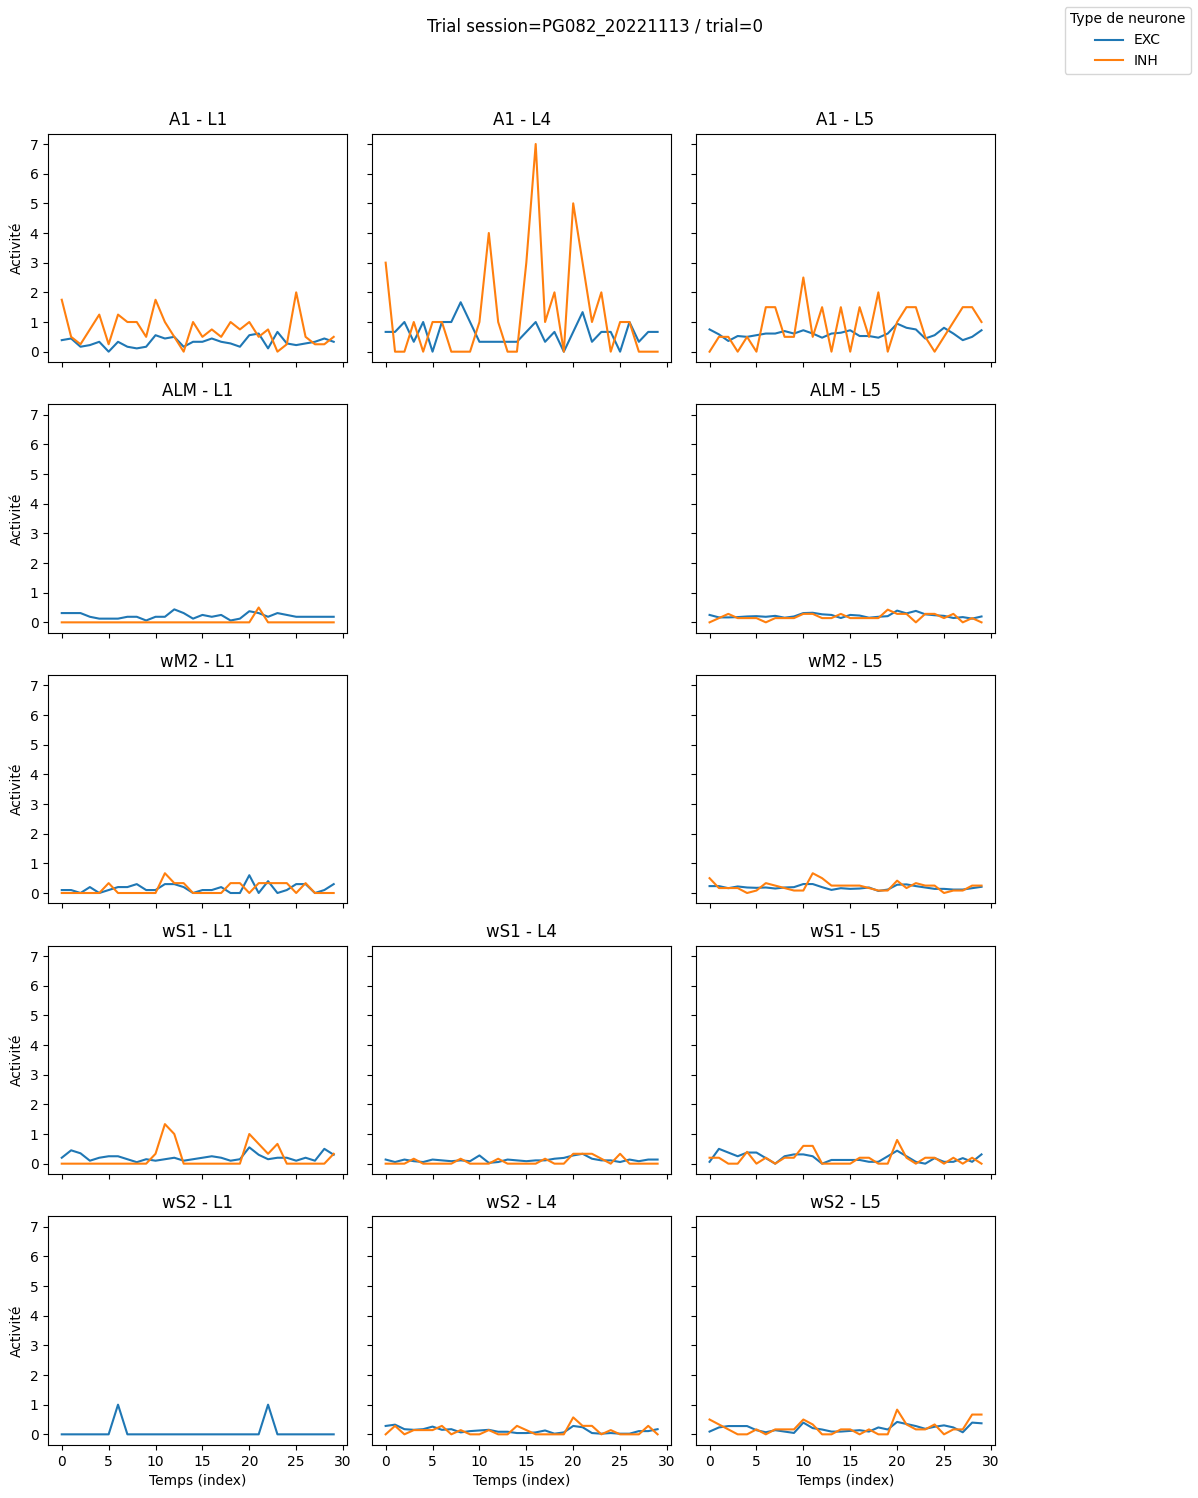

In [9]:

df = pd.read_csv("data/raw/train.csv")

# 1. Charger le train set
df = pd.read_csv("data/raw/train.csv")

# 1bis. Imputer les NaN par la moyenne conditionnelle au TRIAL_TYPE
# On détecte la colonne de cible contenant "trial_type" (insensible à la casse)
target_candidates = [c for c in df.columns if c.lower() == "trial_type"] or [
    c for c in df.columns if "trial_type" in c.lower()
]
if not target_candidates:
    raise ValueError("Colonne TRIAL_TYPE introuvable pour l'imputation conditionnelle.")
target_col = target_candidates[0]

# Colonnes neurones uniquement (on exclut les métadonnées)
pattern = re.compile(r'(?P<region>[^_]+)_(?P<layer>L\d+)_(?P<ctype>[^_]+)_time_(?P<t>\d+)')
neural_cols = [col for col in df.columns if pattern.match(col)]

# Moyennes par type de trial puis remplissage
group_means = df.groupby(target_col)[neural_cols].transform("mean")
df[neural_cols] = df[neural_cols].fillna(group_means)

# 2. On prend un trial (ici la première ligne)
row = df.iloc[0]

# 3. Transformer les colonnes neurones en format "long"
#    Colonnes du type : REGION_LAYER_TYPE_time_T
records = []
for col, val in row.items():
    m = pattern.match(col)
    if m:
        d = m.groupdict()
        d["time"] = int(d.pop("t"))
        d["value"] = float(val)
        records.append(d)

long_df = pd.DataFrame(records)

# 4. Récupérer les régions / couches / types présents
regions = sorted(long_df["region"].unique())
layers  = sorted(long_df["layer"].unique())
ctypes  = sorted(long_df["ctype"].unique())

# 5. Créer la grille de subplots : lignes = régions, colonnes = couches
n_rows = len(regions)
n_cols = len(layers)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4 * n_cols, 3 * n_rows),
                         sharex=True, sharey=True)

# Normaliser axes pour gérer les cas 1x1, 1xn, nx1
if n_rows == 1 and n_cols == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = axes[np.newaxis, :]
elif n_cols == 1:
    axes = axes[:, np.newaxis]

# 6. Boucle sur (région, couche) et tracé d'une courbe par type de neurone
for i, region in enumerate(regions):
    for j, layer in enumerate(layers):
        ax = axes[i, j]

        sub = long_df[(long_df["region"] == region) &
                      (long_df["layer"]  == layer)]

        if sub.empty:
            ax.set_axis_off()
            continue

        for c in ctypes:
            sub_c = sub[sub["ctype"] == c].sort_values("time")
            if sub_c.empty:
                continue
            ax.plot(sub_c["time"], sub_c["value"], label=c)

        ax.set_title(f"{region} - {layer}")
        if i == n_rows - 1:
            ax.set_xlabel("Temps (index)")
        if j == 0:
            ax.set_ylabel("Activité")

# 7. Légende (prise sur le premier subplot non vide)
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right", title="Type de neurone")

fig.suptitle(f"Trial session={row['session_id']} / trial={row['trial_number']}",
             y=0.99)
fig.tight_layout(rect=[0, 0, 0.85, 0.96])

plt.show()


In [7]:
#KNNI imputer and finding best parameters

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

from sklearn.impute import KNNImputer

# Charger le dataset
df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1] # Remove constant columns

# Features et labels
X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

# ======== IMPUTATION AVEC KNNImputer ========
imputer = KNNImputer(n_neighbors=5)
X_train = imputer.fit_transform(X_train)
X_test  = imputer.transform(X_test)
# ===============================================================

# Grid simple pour C et pénalité
I = np.linspace(0.0001, 1, 10)

best_acc = 0
best_C = None
best_l = None

for i in I:
    for l in ["l1", "l2"]:
        model = LogisticRegression(
            penalty=l,
            C=i,
            max_iter=1000,
            solver="liblinear"  # supporte L1 et L2
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        if acc > best_acc:
            best_acc = acc
            best_C = i
            best_l = l

print("Best accuracy:", best_acc)
print("Best penalty:", best_l)
print("Best C:", best_C)

# ----- Re-train best model -----
best_model = LogisticRegression(
    penalty=best_l,
    C=best_C,
    max_iter=1000,
    solver="liblinear"
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is depreca

Best accuracy: 0.6787603930461074
Best penalty: l1
Best C: 0.11120000000000001


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Confusion matrix:
 [[213   0   0   5   0   8   0   0   1   6]
 [  7   0   0   1   0  35   0   0   0  11]
 [  5   0   0  18   0   0   0   2   0   0]
 [  2   0   0 156   0   4   0  61   0  10]
 [ 18   0   0   0   0   2   0   0   1   1]
 [ 11   0   0   8   0 154   0  14   1  57]
 [  1   0   0   0   0   0   0   0   0   0]
 [  2   0   0  41   0   8   0 197   0  10]
 [ 13   0   0   0   0   0   0   0   7  15]
 [  2   0   0   3   0  37   0   4   0 171]]
Accuracy: 0.6787603930461074


In [7]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.impute import KNNImputer
# Best penalty: l1
# Best C: 0.11120000000000001

df = pd.read_csv("data/raw/train.csv")
df = df.loc[:, df.nunique() > 1]  # Remove constant columns


X = df.drop(columns=["session_id", "trial_number", "TRIAL_TYPE"])
y = df["TRIAL_TYPE"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
imputer = KNNImputer(n_neighbors=3)
X_train = imputer.fit_transform(X_train)
X_test  = imputer.transform(X_test)

best_model = LogisticRegression(
    penalty="l1",
    C=0.11120000000000001,
    max_iter=2000,
    solver="liblinear"
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Confusion matrix:
 [[214   0   0   4   0   7   0   1   1   6]
 [  4   0   0   1   0  32   0   1   0  16]
 [  5   0   0  19   0   0   0   1   0   0]
 [  4   0   0 154   0   5   0  60   0  10]
 [ 18   0   0   0   0   2   0   0   1   1]
 [ 10   0   0   7   0 155   0  16   1  56]
 [  1   0   0   0   0   0   0   0   0   0]
 [  1   0   0  42   0   9   0 197   0   9]
 [ 13   0   0   0   0   0   0   0   6  16]
 [  2   0   0   4   0  33   0   5   0 173]]
Accuracy: 0.6795162509448224


The results are always in [0,67, 0,68] range and increase with n and C but actually the result on Kaggle is 0,45 approx. We are clearly overfitting, surely on the mouse ie the model learn the per sesssion behaviour and not the general response. 

### Grid search 

To avoid session-related bias, all hyperparameters were selected using a leave-one-session-out (LOSO) cross-validation strategy. Rather than performing a single exhaustive grid search, hyperparameter tuning was conducted hierarchically. First, the feature representation was selected by comparing the full feature set to ANOVA-based feature selection with varying numbers of retained features. Using the best-performing representation, the imputation strategy was then optimized. Next, the regularization type of the logistic regression model was selected, and finally the regularization strength was fine-tuned. This staged procedure reduced computational cost while ensuring robust cross-session generalization.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# =============================
# 1. Chargement du train
# =============================
df = pd.read_csv("data/raw/train.csv")

# On enlève les colonnes constantes (sauf les identifiants / label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# =============================
# 2. Normalisation PAR SESSION
# =============================
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# z-score à l'intérieur de chaque session (chaque souris)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].copy()
y = df["TRIAL_TYPE"].copy()
groups = df["session_id"].copy()   # pour LOSO

# =============================
# 3. Leave-One-Session-Out CV
# =============================
logo = LeaveOneGroupOut()

C_grid = np.linspace(0.2, 0.4, 10)
penalty = "l1"

best_acc = 0.0
best_C = None
n = 2


for C in C_grid:
    fold_accs = []  # ⚠️ réinitialisé pour chaque (n, C)

    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train_cv = X.iloc[train_idx]
        X_test_cv  = X.iloc[test_idx]
        y_train_cv = y.iloc[train_idx]
        y_test_cv  = y.iloc[test_idx]

        # Imputation DANS le fold uniquement
        imputer = KNNImputer(n_neighbors=n)
        X_train_imp = imputer.fit_transform(X_train_cv)
        X_test_imp  = imputer.transform(X_test_cv)

        model = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",
            max_iter=2000
        )

        model.fit(X_train_imp, y_train_cv)
        y_pred = model.predict(X_test_imp)
        acc = accuracy_score(y_test_cv, y_pred)
        fold_accs.append(acc)

    mean_acc = np.mean(fold_accs)
    print(f"n_neighbors={n}, C={C} => mean LOSO accuracy: {mean_acc:.4f}")

    if mean_acc > best_acc:
        best_acc = mean_acc
        best_C = C
        best_n = n

print("\n=============================")
print(f"Best mean LOSO accuracy: {best_acc:.4f}")
print(f"Best n_neighbors: {best_n}")
print(f"Best C: {best_C}")
print("=============================\n")

# =============================
# 4. Refit final sur tout le train
# =============================
imputer_best = KNNImputer(n_neighbors=best_n)
X_imp_full = imputer_best.fit_transform(X)

model_best = LogisticRegression(
    penalty=penalty,
    C=best_C,
    solver="liblinear",
    max_iter=2000
)
model_best.fit(X_imp_full, y)



# =============================
# Best mean LOSO accuracy: 0.5118
# Best n_neighbors: 2
# Best C: 0.03
# =============================

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression

# =============================
# 1. Charger le train et prétraiter
# =============================
df_train = pd.read_csv("data/raw/train.csv")

# Colonnes constantes (on garde les IDs + label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df_train.columns
    if c not in cols_to_keep and df_train[c].nunique() <= 1
]
df_train = df_train.drop(columns=constant_cols)

# Colonnes de features
feature_cols = [
    c for c in df_train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# Normalisation PAR SESSION (z-score par session_id)
df_train[feature_cols] = df_train.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X_train = df_train[feature_cols].copy()
y_train = df_train["TRIAL_TYPE"].copy()

# =============================
# 2. Définir et entraîner le meilleur modèle
# =============================
best_n = 2      # trouvé précédemment
best_C = 0.03   # trouvé précédemment

imputer_best = KNNImputer(n_neighbors=best_n)
X_train_imp = imputer_best.fit_transform(X_train)

model_best = LogisticRegression(
    penalty="l1",
    C=best_C,
    solver="liblinear",
    max_iter=2000
)
model_best.fit(X_train_imp, y_train)

# =============================
# 3. Charger et prétraiter le test
# =============================
df_test = pd.read_csv("data/raw/test.csv")

# Enlever les mêmes colonnes constantes que dans le train
df_test = df_test.drop(columns=[c for c in constant_cols if c in df_test.columns])

# Normalisation PAR SESSION sur le test (même logique que pour le train)
feat_test = [c for c in df_test.columns if c not in ["session_id", "trial_number"]]
df_test[feat_test] = df_test.groupby("session_id")[feat_test].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# Remettre les colonnes exactement comme dans X_train
# (si une colonne manque, elle sera remplie par NaN puis imputée)
X_test = df_test.reindex(columns=feature_cols)

# Imputation avec l'imputer entraîné sur tout le train
X_test_imp = imputer_best.transform(X_test)

# =============================
# 4. Prédictions et fichier de soumission
# =============================
y_test_pred = model_best.predict(X_test_imp)

sub = pd.read_csv("data/raw/sample_submission.csv")
sub["TRIAL_TYPE"] = y_test_pred

output_path = "data/submission_logreg_l1_loso.csv"
sub.to_csv(output_path, index=False)

print(f"Fichier de soumission écrit dans {output_path}")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fichier de soumission écrit dans data/submission_logreg_l1_loso.csv
X_train shape: (4407, 1350), X_test shape: (2292, 1350)


### Logistic Regression on the selected 400 features 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression

# =============================
# 1. Charger le train et prétraiter
# =============================
df_train = pd.read_csv("data/raw/train.csv")

# Colonnes constantes (on garde les IDs + label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df_train.columns
    if c not in cols_to_keep and df_train[c].nunique() <= 1
]
df_train = df_train.drop(columns=constant_cols)

# Colonnes de features
feature_cols = [
    c for c in df_train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# Normalisation PAR SESSION (z-score par session_id)
df_train[feature_cols] = df_train.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X_train = df_train[feature_cols].copy()
y_train = df_train["TRIAL_TYPE"].copy()

# =============================
# 2. Définir et entraîner le meilleur modèle
# =============================
best_n = 2      # trouvé précédemment
best_C = 0.03   # trouvé précédemment

imputer_best = KNNImputer(n_neighbors=best_n)
X_train_imp = imputer_best.fit_transform(X_train)

model_best = LogisticRegression(
    penalty="l1",
    C=best_C,
    solver="liblinear",
    max_iter=2000
)
model_best.fit(X_train_imp, y_train)

# # =============================
# # 3. Charger et prétraiter le test
# # =============================
# df_test = pd.read_csv("data/raw/test.csv")

# # Enlever les mêmes colonnes constantes que dans le train
# df_test = df_test.drop(columns=[c for c in constant_cols if c in df_test.columns])

# # Normalisation PAR SESSION sur le test (même logique que pour le train)
# feat_test = [c for c in df_test.columns if c not in ["session_id", "trial_number"]]
# df_test[feat_test] = df_test.groupby("session_id")[feat_test].transform(
#     lambda x: (x - x.mean()) / (x.std() + 1e-8)
#)

# # Remettre les colonnes exactement comme dans X_train
# # (si une colonne manque, elle sera remplie par NaN puis imputée)
# X_test = df_test.reindex(columns=feature_cols)

# # Imputation avec l'imputer entraîné sur tout le train
# X_test_imp = imputer_best.transform(X_test)

# # =============================
# # 4. Prédictions et fichier de soumission
# # =============================
# y_test_pred = model_best.predict(X_test_imp)

# sub = pd.read_csv("data/raw/sample_submission.csv")
# sub["TRIAL_TYPE"] = y_test_pred

# output_path = "data/submission_logreg_l1_loso_400.csv"
# sub.to_csv(output_path, index=False)

# print(f"Fichier de soumission écrit dans {output_path}")
# print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fichier de soumission écrit dans data/submission_logreg_l1_loso_400.csv
X_train shape: (4407, 1350), X_test shape: (2292, 1350)


Test to normalize per baseline instead of z-score

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# =============================
# Params
# =============================
TRAIN_PATH = "data/raw/train.csv"
best_n = 2
best_C = 0.03
K_BEST = 400
baseline_bins = set(range(0, 10))  # 0..9

# =============================
# Load + features
# =============================
df = pd.read_csv(TRAIN_PATH)

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]
all_feat_cols = [c for c in df.columns if c not in ID_COLS]

# drop colonnes constantes
const_cols = [c for c in all_feat_cols if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=const_cols)
all_feat_cols = [c for c in all_feat_cols if c not in const_cols]

# numeric (évite dtype object)
df[all_feat_cols] = df[all_feat_cols].apply(pd.to_numeric, errors="coerce")

# garder uniquement les features temporelles
time_cols = [c for c in all_feat_cols if "_time_" in c]

# mapping signal -> cols + time index
signal_cols = {}
col_time = {}
for c in time_cols:
    sig, t = c.rsplit("_time_", 1)
    signal_cols.setdefault(sig, []).append(c)
    col_time[c] = int(t)
for sig in signal_cols:
    signal_cols[sig].sort(key=lambda c: col_time[c])

def baseline_session(df_part):
    """Soustrait, pour chaque signal, la moyenne (sur toute la session) des bins 0..9."""
    X = df_part[time_cols].copy()
    for sig, cols in signal_cols.items():
        base_cols = [c for c in cols if col_time[c] in baseline_bins]
        if not base_cols:
            continue
        b = X[base_cols].to_numpy().mean()   # moyenne globale de baseline dans la session
        X[cols] = X[cols] - b
    return X

# =============================
# LOSO + top-400 dans chaque fold
# =============================
logo = LeaveOneGroupOut()
y_all = df["TRIAL_TYPE"]
g_all = df["session_id"]

accs = []

for fold, (tr_idx, va_idx) in enumerate(logo.split(df, y_all, groups=g_all), start=1):
    df_tr = df.iloc[tr_idx]
    df_va = df.iloc[va_idx]

    # Baseline (fait séparément train/val)
    X_tr = baseline_session(df_tr)
    X_va = baseline_session(df_va)

    # Imputation (fit sur train fold uniquement)
    imp = KNNImputer(n_neighbors=best_n)
    X_tr_imp = imp.fit_transform(X_tr)
    X_va_imp = imp.transform(X_va)

    # Sélection top-400 sur train fold uniquement (pas de fuite)
    f_scores, _ = f_classif(X_tr_imp, y_all.iloc[tr_idx])
    f_scores = np.nan_to_num(f_scores, nan=-np.inf)

    k = min(K_BEST, X_tr_imp.shape[1])
    best_idx = np.argsort(f_scores)[-k:]  # indices des meilleures features

    X_tr_sel = X_tr_imp[:, best_idx]
    X_va_sel = X_va_imp[:, best_idx]

    # Modèle (identique à ton pipeline)
    model = LogisticRegression(
        penalty="l1",
        C=best_C,
        solver="liblinear",
        max_iter=2000
    )
    model.fit(X_tr_sel, y_all.iloc[tr_idx])

    y_pred = model.predict(X_va_sel)
    acc = accuracy_score(y_all.iloc[va_idx], y_pred)
    accs.append(acc)

    # (optionnel) print par fold
    sid = g_all.iloc[va_idx].iloc[0]
    print(f"Fold {fold:03d} | val_session={sid} | acc={acc:.4f} | k={k}")

print(f"\nLOSO mean acc = {np.mean(accs):.4f}  (+/- {np.std(accs):.4f})")


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 001 | val_session=PG082_20221113 | acc=0.3308 | k=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 002 | val_session=PG082_20221114 | acc=0.4886 | k=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


...

Fold 006 | val_session=PG084_20221207 | acc=0.4535 | k=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 007 | val_session=PG085_20221213 | acc=0.2927 | k=400


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Fold 008 | val_session=PG085_20221214 | acc=0.4748 | k=400

LOSO mean acc = 0.4356  (+/- 0.0732)


# Reducing the dataset 

We could use L1 regularisation, PCA or ANOVA. L1 reg is already used in the model (and put some features to 0) and more focus on the multivariate behaviour. PCA don't focus on the TRIAL_TYPE and only focus on explained variance in the X set. Anova correctly keeps features depending on F-score which depends on the explained univariate variance.  

### visulaizing F-scores

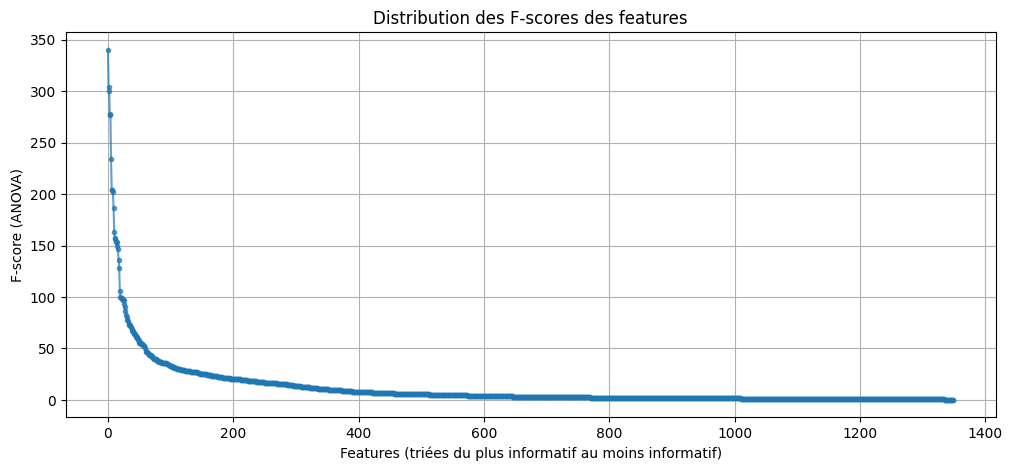

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer
from sklearn.feature_selection import f_classif

# =============================
# 1. Chargement du train
# =============================
df = pd.read_csv("data/raw/train.csv")

# Supprimer colonnes constantes
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# =============================
# 2. Normalisation PAR SESSION
# =============================
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].copy()
y = df["TRIAL_TYPE"].copy()

# =============================
# 3. Imputation temporaire pour faire ANOVA correctement
# =============================
imputer = KNNImputer(n_neighbors=2)
X_imp = imputer.fit_transform(X)

# =============================
# 4. Calcul ANOVA F-test
# =============================
F_scores, _ = f_classif(X_imp, y)

# Tri décroissant pour visualisation
F_sorted = np.sort(F_scores)[::-1]

# =============================
# 5. Plot des F-scores
# =============================
plt.figure(figsize=(12,5))
plt.plot(F_sorted, marker='.', linestyle='-', alpha=0.7)
plt.xlabel("Features (triées du plus informatif au moins informatif)")
plt.ylabel("F-score (ANOVA)")
plt.title("Distribution des F-scores des features")
plt.grid(True)
plt.show()

we clearly see that some features explain a lot of variance and some not. We need to understand if the explaining features have something in common and lastly we'll cut the dataset to conserve only the explaining data. To select the best k features we graphically select the a little bit after the "knee" of F-score distributions which is arround 50. 

Features totales : 1350
Top features gardées : 400


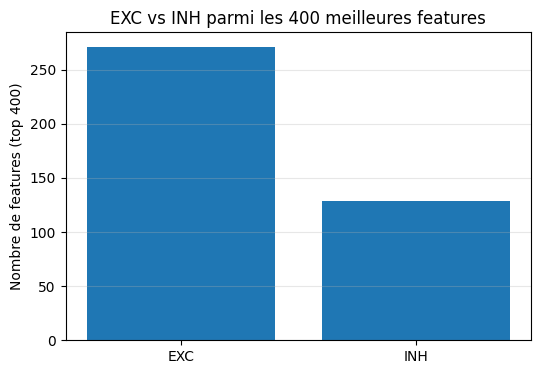

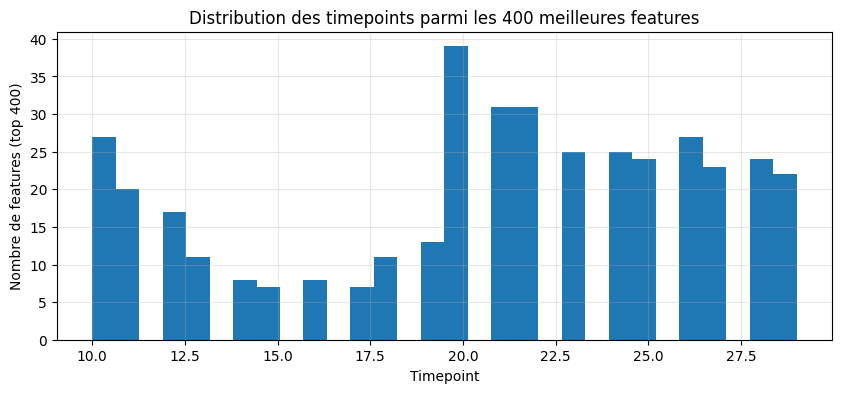

In [8]:
from collections import Counter

n_top = 400
idx_sorted = np.argsort(F_scores)[::-1]
top_idx = idx_sorted[:n_top]

top_features = [feature_cols[i] for i in top_idx]
top_F = F_scores[top_idx]

print(f"Features totales : {len(feature_cols)}")
print(f"Top features gardées : {len(top_features)}")

# =============================
# 6. Fonctions simples pour type (EXC/INH) et timepoint
# =============================
def get_cell_type(name: str) -> str:
    # Ex: "A1_L1_EXC_time_0" -> "EXC"
    parts = name.split("_")
    if "EXC" in parts:
        return "EXC"
    if "INH" in parts:
        return "INH"
    return "UNKNOWN"

def get_timepoint(name: str):
    # Ex: "A1_L1_EXC_time_0" -> 0
    parts = name.split("_")
    if "time" in parts:
        i = parts.index("time")
        if i + 1 < len(parts):
            try:
                return int(parts[i + 1])
            except ValueError:
                return None
    # fallback: essayer dernier bout
    try:
        return int(parts[-1])
    except ValueError:
        return None

cell_types = []
timepoints = []
for f in top_features:
    cell_types.append(get_cell_type(f))
    tp = get_timepoint(f)
    if tp is not None:
        timepoints.append(tp)

# =============================
# 7. Plot EXC vs INH
# =============================
counts = Counter(cell_types)

plt.figure(figsize=(6, 4))
plt.bar(list(counts.keys()), list(counts.values()))
plt.ylabel("Nombre de features (top 400)")
plt.title("EXC vs INH parmi les 400 meilleures features")
plt.grid(axis="y", alpha=0.3)
plt.show()

# =============================
# 8. Plot distribution des timepoints
# =============================
plt.figure(figsize=(10, 4))
plt.hist(timepoints, bins=30)
plt.xlabel("Timepoint")
plt.ylabel("Nombre de features (top 400)")
plt.title("Distribution des timepoints parmi les 400 meilleures features")
plt.grid(True, alpha=0.3)
plt.show()

We have massive insight from these 2 plots. The first is that exc neurons are more "involved" or explicative in this dataset but the most important is in the second: every thing happening before the first stimulation (tone) is noise. It's logic and was our hypothesis because for each trial, we've the same "initial conditions"; the plot comfirm our hypothesis. 

In [10]:
cols_final = ["session_id", "trial_number", "TRIAL_TYPE"] + top_features
df_reduced = df[cols_final].copy()

# =============================
# 11. Sauvegarder dans data/processed
# =============================
output_path = "data/train_reduced_400.csv"
df_reduced.to_csv(output_path, index=False)

print(f"Dataset réduit sauvegardé dans : {output_path}")
print("Taille originale :", df.shape, 
      " → Taille réduite :", df_reduced.shape)

Dataset réduit sauvegardé dans : data/train_reduced_400.csv
Taille originale : (4407, 1353)  → Taille réduite : (4407, 403)


# Non-Linear Model 

In [11]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

# =============================
# 1. Chargement du train réduit
# =============================
df = pd.read_csv("data/train_reduced_400.csv")

print(df.shape)
print(df.columns[:10])

# Colonnes de features
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Encodage des labels (XGBoost veut des entiers)
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# =============================
# 2. LOSO CV avec XGBoost + KNNImputer
# =============================
logo = LeaveOneGroupOut()
fold_accs = []

for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    X_train_raw = X[train_idx]
    X_test_raw  = X[test_idx]
    y_train = y[train_idx]
    y_test  = y[test_idx]
    test_sessions = np.unique(groups[test_idx])

    # --- Imputation dans le fold (pas de leakage)
    imputer = KNNImputer(n_neighbors=2)
    X_train = imputer.fit_transform(X_train_raw)
    X_test  = imputer.transform(X_test_raw)

    # --- Modèle XGBoost
    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    fold_accs.append(acc)

    print(f"Fold {fold} – test sessions {test_sessions} – accuracy: {acc:.4f}")

mean_acc = np.mean(fold_accs)
print("\n=============================")
print(f"Mean LOSO accuracy (XGBoost, train_reduced_400) : {mean_acc:.4f}")
print("=============================\n")

# =============================
# 3. Refit final sur tout le train réduit
# =============================

imputer_final = KNNImputer(n_neighbors=2)
X_imp_full = imputer_final.fit_transform(X)

model_final = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=num_classes,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=0,
    n_jobs=-1,
)

model_final.fit(X_imp_full, y)
print("Modèle final XGBoost entraîné sur tout train_reduced_400.")


(4407, 403)
Index(['session_id', 'trial_number', 'TRIAL_TYPE', 'ALM_L5_EXC_time_22',
       'ALM_L5_EXC_time_21', 'ALM_L5_EXC_time_23', 'wS1_L4_EXC_time_20',
       'ALM_L5_EXC_time_20', 'ALM_L5_EXC_time_24', 'wS2_L4_EXC_time_20'],
      dtype='object')
Fold 1 – test sessions ['PG082_20221113'] – accuracy: 0.5755
Fold 2 – test sessions ['PG082_20221114'] – accuracy: 0.6319
Fold 3 – test sessions ['PG083_20221125'] – accuracy: 0.5802
Fold 4 – test sessions ['PG083_20221129'] – accuracy: 0.5210
Fold 5 – test sessions ['PG084_20221206'] – accuracy: 0.5413
Fold 6 – test sessions ['PG084_20221207'] – accuracy: 0.5665
Fold 7 – test sessions ['PG085_20221213'] – accuracy: 0.4522
Fold 8 – test sessions ['PG085_20221214'] – accuracy: 0.5917

Mean LOSO accuracy (XGBoost, train_reduced_400) : 0.5575

Modèle final XGBoost entraîné sur tout train_reduced_400.


### Hyperparameters fitting
max_depth learning_rate n_estimators

In [12]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

# =============================
# 1. Chargement du train réduit
# =============================
df = pd.read_csv("data/train_reduced_400.csv")

# Colonnes de features
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Encodage des labels en entiers
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)

# =============================
# 2. Définition de la grille étendue
# =============================

param_grid = [
    # (max_depth, learning_rate, n_estimators)
    {"max_depth": 3, "learning_rate": 0.10, "n_estimators": 150},
    {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 300},#EXPLAIN !!!!
    {"max_depth": 4, "learning_rate": 0.10, "n_estimators": 150},
    {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 300},
    {"max_depth": 5, "learning_rate": 0.10, "n_estimators": 150},
    {"max_depth": 5, "learning_rate": 0.05, "n_estimators": 300},

    # nouveaux configs plus complexes
    {"max_depth": 6, "learning_rate": 0.10, "n_estimators": 150},
    {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 300},
    {"max_depth": 6, "learning_rate": 0.03, "n_estimators": 400},
]

logo = LeaveOneGroupOut()

best_params = None
best_mean_acc = -np.inf
results = []

# =============================
# 3. Boucle sur les combos d'hyperparams
# =============================
for params in param_grid:
    md = params["max_depth"]
    lr = params["learning_rate"]
    ne = params["n_estimators"]

    fold_test_accs = []
    fold_train_accs = []

    print(f"\n=== Test config: max_depth={md}, learning_rate={lr}, n_estimators={ne} ===")

    for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
        X_train_raw = X[train_idx]
        X_test_raw  = X[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]
        test_sessions = np.unique(groups[test_idx])

        # --- Imputation dans le fold (pas de leakage)
        imputer = KNNImputer(n_neighbors=2)
        X_train = imputer.fit_transform(X_train_raw)
        X_test  = imputer.transform(X_test_raw)

        # --- Modèle XGBoost avec les hyperparams en cours
        model = XGBClassifier(
            n_estimators=ne,
            max_depth=md,
            learning_rate=lr,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
        )

        model.fit(X_train, y_train)

        # --- Accuracy sur le test fold
        y_pred_test = model.predict(X_test)
        acc_test = accuracy_score(y_test, y_pred_test)
        fold_test_accs.append(acc_test)

        # --- Accuracy sur le train fold (pour voir l'overfit)
        y_pred_train = model.predict(X_train)
        acc_train = accuracy_score(y_train, y_pred_train)
        fold_train_accs.append(acc_train)

        print(
            f"  Fold {fold} – test sessions {test_sessions} – "
            f"train_acc={acc_train:.4f} – test_acc={acc_test:.4f}"
        )

    mean_test_acc = np.mean(fold_test_accs)
    mean_train_acc = np.mean(fold_train_accs)

    results.append((params, mean_train_acc, mean_test_acc))

    print(f"--> Mean LOSO accuracy TRAIN : {mean_train_acc:.4f}")
    print(f"--> Mean LOSO accuracy TEST  : {mean_test_acc:.4f}")

    if mean_test_acc > best_mean_acc:
        best_mean_acc = mean_test_acc
        best_params = params

print("\n====================================")
print("Résultats récapitulatifs :")
for params, acc_train, acc_test in results:
    print(
        f"max_depth={params['max_depth']}, lr={params['learning_rate']}, "
        f"n_estimators={params['n_estimators']} "
        f"-> mean TRAIN acc={acc_train:.4f}, mean TEST acc={acc_test:.4f}"
    )

print("\nMeilleure config trouvée (sur TEST) :")
print(best_params, "avec mean LOSO TEST accuracy =", f"{best_mean_acc:.4f}")
print("====================================")


Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']

=== Test config: max_depth=3, learning_rate=0.1, n_estimators=150 ===
  Fold 1 – test sessions ['PG082_20221113'] – train_acc=0.9744 – test_acc=0.5710
  Fold 2 – test sessions ['PG082_20221114'] – train_acc=0.9690 – test_acc=0.6319
  Fold 3 – test sessions ['PG083_20221125'] – train_acc=0.9783 – test_acc=0.5849
  Fold 4 – test sessions ['PG083_20221129'] – train_acc=0.9755 – test_acc=0.5210
  Fold 5 – test sessions ['PG084_20221206'] – train_acc=0.9777 – test_acc=0.5295
  Fold 6 – test sessions ['PG084_20221207'] – train_acc=0.9806 – test_acc=0.5838
  Fold 7 – test sessions ['PG085_20221213'] – train_acc=0.9786 – test_acc=0.4428
  Fold 8 – test sessions ['PG085_20221214'] – train_acc=0.9746 – test_acc=0.5827
--> Mean LOSO accuracy TRAIN : 0.9761
--> Mean LOSO accuracy TEST  : 0.5560

=== Test config: max_depth=3, le

KeyboardInterrupt: 

After max_depth = 3 we don't significatively reach better accuraccy on the train but reach near 1 for the train which could indicate an overfit. We select {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 300}

### Finding best parameter for regularization (min_child_weight, L1, L2)

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

# =============================
# 1. Chargement du train réduit
# =============================
df = pd.read_csv("data/train_reduced_400.csv")

# Colonnes de features
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)

# =======================================================
# 2. Hyperparams "structurels" déjà validés
#    (on ne touche plus à ces valeurs)
# =======================================================
base_depth = 3
base_lr = 0.05
base_estimators = 300

# =======================================================
# 3. Grille de régularisation (L1, L2, min_child_weight)
# =======================================================
lambda_grid = [0.5, 1.0, 2.0, 5.0]   # L2 (reg_lambda)
alpha_grid  = [0.0, 0.1, 0.5]        # L1 (reg_alpha)
mcw_grid    = [1, 3, 5]              # min_child_weight

logo = LeaveOneGroupOut()

results = []
best_acc = -np.inf
best_params = None

for reg_l in lambda_grid:
    for reg_a in alpha_grid:
        for mcw in mcw_grid:

            fold_train_accs = []
            fold_test_accs = []

            print(f"\n=== Test config: reg_lambda={reg_l}, reg_alpha={reg_a}, "
                  f"min_child_weight={mcw} ===")

            for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
                X_train_raw = X[train_idx]
                X_test_raw  = X[test_idx]
                y_train = y[train_idx]
                y_test  = y[test_idx]

                # Imputation sans leakage
                imputer = KNNImputer(n_neighbors=2)
                X_train = imputer.fit_transform(X_train_raw)
                X_test  = imputer.transform(X_test_raw)

                # =============================
                # Modèle XGBoost épuré :
                #   - on garde seulement les params utiles
                #   - on grid-search uniquement la régularisation
                # =============================
                model = XGBClassifier(
                    n_estimators=base_estimators,
                    max_depth=base_depth,
                    learning_rate=base_lr,

                    reg_lambda=reg_l,        # L2
                    reg_alpha=reg_a,         # L1
                    min_child_weight=mcw,    # régularisation structurelle

                    objective="multi:softprob",
                    num_class=num_classes,
                    random_state=0,
                )

                model.fit(X_train, y_train)

                # Accuracy TRAIN (pour voir l’overfit)
                y_pred_train = model.predict(X_train)
                acc_train = accuracy_score(y_train, y_pred_train)
                fold_train_accs.append(acc_train)

                # Accuracy TEST (LOSO)
                y_pred_test = model.predict(X_test)
                acc_test = accuracy_score(y_test, y_pred_test)
                fold_test_accs.append(acc_test)

                print(f"  Fold {fold} – train_acc={acc_train:.4f} – test_acc={acc_test:.4f}")

            mean_train_acc = np.mean(fold_train_accs)
            mean_test_acc = np.mean(fold_test_accs)

            results.append((reg_l, reg_a, mcw, mean_train_acc, mean_test_acc))

            print(f"--> Mean LOSO TRAIN accuracy : {mean_train_acc:.4f}")
            print(f"--> Mean LOSO TEST  accuracy : {mean_test_acc:.4f}")

            # Sélection sur la perf TEST
            if mean_test_acc > best_acc:
                best_acc = mean_test_acc
                best_params = {
                    "reg_lambda": reg_l,
                    "reg_alpha": reg_a,
                    "min_child_weight": mcw,
                    "mean_train_acc": mean_train_acc,
                    "mean_test_acc": mean_test_acc,
                }

# Résumé final
print("\n===============================")
print("Résultats récapitulatifs :")
for reg_l, reg_a, mcw, acc_tr, acc_te in results:
    print(
        f"lambda={reg_l}, alpha={reg_a}, mcw={mcw} "
        f"-> mean TRAIN acc={acc_tr:.4f}, mean TEST acc={acc_te:.4f}"
    )

print("\nMeilleurs paramètres de régularisation trouvés :")
print(best_params)
print("===============================")


Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']

=== Test config: reg_lambda=0.5, reg_alpha=0.0, min_child_weight=1 ===
  Fold 1 – train_acc=0.9714 – test_acc=0.5710
  Fold 2 – train_acc=0.9654 – test_acc=0.6026
  Fold 3 – train_acc=0.9777 – test_acc=0.5723
  Fold 4 – train_acc=0.9719 – test_acc=0.5121
  Fold 5 – train_acc=0.9751 – test_acc=0.5413
  Fold 6 – train_acc=0.9751 – test_acc=0.5625
  Fold 7 – train_acc=0.9734 – test_acc=0.4465
  Fold 8 – train_acc=0.9738 – test_acc=0.5683
--> Mean LOSO TRAIN accuracy : 0.9730
--> Mean LOSO TEST  accuracy : 0.5471

=== Test config: reg_lambda=0.5, reg_alpha=0.0, min_child_weight=3 ===
  Fold 1 – train_acc=0.9674 – test_acc=0.5725
  Fold 2 – train_acc=0.9612 – test_acc=0.6026
  Fold 3 – train_acc=0.9761 – test_acc=0.5786
  Fold 4 – train_acc=0.9689 – test_acc=0.5121
  Fold 5 – train_acc=0.9710 – test_acc=0.5315
  Fold 6 –

best parameters after grid search 
max_depth = 3
learning_rate = 0.05
n_estimators = 300
reg_lambda = 5 
reg_alpha = 0.1
min_child_weight = 3

### Another iteration for finding the best imputer 

In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

# =============================
# 1. Chargement du train réduit
# =============================
df = pd.read_csv("data/train_reduced_400.csv")

# Colonnes de features (les 400 sélectionnées)
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Encodage des labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)

# =============================
# 2. Hyperparams XGBoost FIXÉS
#    (trouvés par grid search régularisation)
# =============================
BEST_MAX_DEPTH = 3
BEST_LR = 0.05
BEST_N_ESTIMATORS = 300
BEST_REG_LAMBDA = 5.0
BEST_REG_ALPHA = 0.1
BEST_MIN_CHILD_WEIGHT = 3

# =============================
# 3. Différents imputers à tester
#    (imputer + paramètres)
# =============================
imputers = {
    "knn_n1": KNNImputer(n_neighbors=1),
    "knn_n2": KNNImputer(n_neighbors=2),
    "knn_n3": KNNImputer(n_neighbors=3),
    "median": SimpleImputer(strategy="median"),
    "mean": SimpleImputer(strategy="mean"),
    "zero": SimpleImputer(strategy="constant", fill_value=0.0),
}

logo = LeaveOneGroupOut()

results = {}
best_imputer_name = None
best_mean_acc = -np.inf

# =============================
# 4. Boucle sur les différents imputers
# =============================
for name, base_imputer in imputers.items():
    fold_accs = []
    print(f"\n=== Test imputer: {name} ===")

    for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
        X_train_raw = X[train_idx]
        X_test_raw  = X[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        # IMPORTANT : recréer un imputer neuf à chaque fold
        # pour éviter tout effet de bord
        from copy import deepcopy
        imputer = deepcopy(base_imputer)

        # Imputation SANS fuite : fit sur train, transform sur test
        X_train = imputer.fit_transform(X_train_raw)
        X_test  = imputer.transform(X_test_raw)

        # Modèle XGBoost avec hyperparams fixés
        model = XGBClassifier(
            n_estimators=BEST_N_ESTIMATORS,
            max_depth=BEST_MAX_DEPTH,
            learning_rate=BEST_LR,
            reg_lambda=BEST_REG_LAMBDA,
            reg_alpha=BEST_REG_ALPHA,
            min_child_weight=BEST_MIN_CHILD_WEIGHT,
            objective="multi:softprob",
            num_class=num_classes,
            random_state=0,
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        fold_accs.append(acc)

        print(f"  Fold {fold} – acc={acc:.4f}")

    mean_acc = np.mean(fold_accs)
    results[name] = mean_acc
    print(f"--> Mean LOSO accuracy ({name}) = {mean_acc:.4f}")

    if mean_acc > best_mean_acc:
        best_mean_acc = mean_acc
        best_imputer_name = name

print("\n===============================")
print("Résultats récapitulatifs :")
for name, acc in results.items():
    print(f"{name} -> mean acc = {acc:.4f}")

print(f"\nMeilleur imputer : {best_imputer_name} avec mean acc = {best_mean_acc:.4f}")
print("===============================")

# =============================
# 5. Entraîner le modèle final
#    avec le meilleur imputer sur tout le train
# =============================
best_imputer = imputers[best_imputer_name]
X_imp_full = best_imputer.fit_transform(X)

model_final = XGBClassifier(
    n_estimators=BEST_N_ESTIMATORS,
    max_depth=BEST_MAX_DEPTH,
    learning_rate=BEST_LR,
    reg_lambda=BEST_REG_LAMBDA,
    reg_alpha=BEST_REG_ALPHA,
    min_child_weight=BEST_MIN_CHILD_WEIGHT,
    objective="multi:softprob",
    num_class=num_classes,
    random_state=0,
)

model_final.fit(X_imp_full, y)
print(f"\nModèle final XGBoost entraîné avec imputer='{best_imputer_name}' sur tout train_reduced_400.")


Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']

=== Test imputer: knn_n1 ===
  Fold 1 – acc=0.5634
  Fold 2 – acc=0.6156
  Fold 3 – acc=0.5770
  Fold 4 – acc=0.5475
  Fold 5 – acc=0.5413
  Fold 6 – acc=0.5559
  Fold 7 – acc=0.4559
  Fold 8 – acc=0.5773
--> Mean LOSO accuracy (knn_n1) = 0.5543

=== Test imputer: knn_n2 ===
  Fold 1 – acc=0.5755
  Fold 2 – acc=0.6091
  Fold 3 – acc=0.5770
  Fold 4 – acc=0.5298
  Fold 5 – acc=0.5295
  Fold 6 – acc=0.5665
  Fold 7 – acc=0.4503
  Fold 8 – acc=0.5845
--> Mean LOSO accuracy (knn_n2) = 0.5528

=== Test imputer: knn_n3 ===
  Fold 1 – acc=0.5725
  Fold 2 – acc=0.6156
  Fold 3 – acc=0.5723
  Fold 4 – acc=0.5254
  Fold 5 – acc=0.5374
  Fold 6 – acc=0.5798
  Fold 7 – acc=0.4465
  Fold 8 – acc=0.5665
--> Mean LOSO accuracy (knn_n3) = 0.5520

=== Test imputer: median ===
  Fold 1 – acc=0.5680
  Fold 2 – acc=0.5928
  Fold 3 – ac

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [349 384 397]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [349 384 397]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fold 8 – acc=0.5468
--> Mean LOSO accuracy (median) = 0.5422

=== Test imputer: mean ===
  Fold 1 – acc=0.5846
  Fold 2 – acc=0.6059
  Fold 3 – acc=0.5912
  Fold 4 – acc=0.5143
  Fold 5 – acc=0.5217
  Fold 6 – acc=0.5452
  Fold 7 – acc=0.4447


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [349 384 397]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [349 384 397]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 8 – acc=0.5486
--> Mean LOSO accuracy (mean) = 0.5445

=== Test imputer: zero ===
  Fold 1 – acc=0.5846
  Fold 2 – acc=0.6059
  Fold 3 – acc=0.5943
  Fold 4 – acc=0.5143
  Fold 5 – acc=0.5217
  Fold 6 – acc=0.5452
  Fold 7 – acc=0.4428


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:590: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(


  Fold 8 – acc=0.5486
--> Mean LOSO accuracy (zero) = 0.5447

Résultats récapitulatifs :
knn_n1 -> mean acc = 0.5543
knn_n2 -> mean acc = 0.5528
knn_n3 -> mean acc = 0.5520
median -> mean acc = 0.5422
mean -> mean acc = 0.5445
zero -> mean acc = 0.5447

Meilleur imputer : knn_n1 avec mean acc = 0.5543

Modèle final XGBoost entraîné avec imputer='knn_n1' sur tout train_reduced_400.


-Just keep best test_accuraccy instead of looking for overfit on the train ?
-train on a variable number of features (not 400)
-normalize differently or don't normalize (different pre-process from logreg)

# Now we've our best parameters we'll check which number of feature can be taken 
to reach the best accurraccy

# submission for non linear model

In [13]:
import pandas as pd
import numpy as np

from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

# =============================
# 1. Charger le train réduit
# =============================
train = pd.read_csv("data/train_reduced_400.csv")

# Features = toutes les colonnes sauf id / trial / label
feature_cols = [
    c for c in train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X_train = train[feature_cols].values
y_train_str = train["TRIAL_TYPE"].values

# Encodage des labels
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)

# =============================
# 2. Imputer + entraîner XGBoost sur tout le train
# =============================
imputer = KNNImputer(n_neighbors=1)
X_train_imp = imputer.fit_transform(X_train)

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    reg_lambda=5.0,        # L2
    reg_alpha=0.1,         # L1
    min_child_weight=3,
    objective="multi:softprob",
    num_class=num_classes,
    random_state=0,
)

model.fit(X_train_imp, y_train)
print("Modèle XGBoost entraîné sur tout train_reduced_400 avec KNNImputer(n_neighbors=1).")

# =============================
# 3. Préparer le test set
# =============================
# On repart du test brut avec TOUTES les colonnes
test_raw = pd.read_csv("data/raw/test.csv")

# On ne garde que les colonnes nécessaires : ids + les 400 features
needed_cols = ["session_id", "trial_number"] + feature_cols
test = test_raw[needed_cols].copy()

# Normalisation PAR SESSION sur les mêmes features
# (doit être cohérent avec la manière dont train_reduced_400 a été construit)
test[feature_cols] = test.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X_test = test[feature_cols].values
X_test_imp = imputer.transform(X_test)

# =============================
# 4. Prédire les labels TRIAL_TYPE
# =============================
y_pred_int = model.predict(X_test_imp)
y_pred_str = le.inverse_transform(y_pred_int)

# =============================
# 5. Construire le fichier de submission
# =============================
sample = pd.read_csv("data/raw/sample_submission.csv")
print(sample.head())

submission = sample.copy()
submission["TRIAL_TYPE"] = y_pred_str

submission.to_csv("submission_xgboost_knn1_bestparams.csv", index=False)
print("Fichier 'submission_xgboost_knn1_bestparams.csv' écrit. Tu peux le déposer sur Kaggle.")


Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Modèle XGBoost entraîné sur tout train_reduced_400 avec KNNImputer(n_neighbors=1).
   ID      TRIAL_TYPE
0   1  NOGO W- nolick
1   2    GO W+ nolick
2   3  NOGO W- nolick
3   4    NOGO W- lick
4   5  NOGO W+ nolick
Fichier 'submission_xgboost_knn1_bestparams.csv' écrit. Tu peux le déposer sur Kaggle.


TODO
remove the overfitting test over the fold for max_depth

In [1]:
import numpy as np
import pandas as pd
import random
from pprint import pprint

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier


# =============================
# 1. Charger le train brut
# =============================
train = pd.read_csv("data/raw/train.csv")

# Colonnes constantes (on les vire, sauf IDs + label)
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in train.columns
    if c not in cols_to_keep and train[c].nunique() <= 1
]
print("Colonnes constantes supprimées :", len(constant_cols))

train = train.drop(columns=constant_cols)

# Features = toutes les colonnes sauf id / trial / label
feature_cols = [
    c for c in train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

print("Nombre de features retenues :", len(feature_cols))

X = train[feature_cols].values      # contient possiblement des NaN
y_str = train["TRIAL_TYPE"].values
groups = train["session_id"].values  # pour LOGO

# Encodage des labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)
print("Nombre de classes :", num_classes)


logo = LeaveOneGroupOut()

def logo_cv_score(params, X, y, groups, verbose=False):
    """
    Évalue un set de paramètres XGBoost par Leave-One-Group-Out (group = session_id).
    Retourne l'accuracy moyenne.
    """
    scores = []

    # Boucle sur chaque session laissée de côté
    for fold_idx, (train_idx, val_idx) in enumerate(logo.split(X, y, groups)):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=num_classes,
            tree_method="hist",   # rapide et adapté aux gros datasets
            eval_metric="mlogloss",
            random_state=0,
            **params,
        )

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        scores.append(acc)

        if verbose:
            print(f"  Fold {fold_idx+1}: acc = {acc:.4f}")

    return float(np.mean(scores))


# =============================
# 4. Espace d'hyperparamètres
# =============================
param_space = {
    "n_estimators":      [300, 600, 900, 1200],
    "max_depth":         [3, 4, 5, 6],
    "learning_rate":     [0.03, 0.05, 0.07, 0.1],
    "min_child_weight":  [1, 2, 3, 5],
    "subsample":         [0.7, 0.85, 1.0],
    "colsample_bytree":  [0.5, 0.7, 0.9],
    "reg_lambda":        [0.0, 1.0, 3.0, 5.0],
    "reg_alpha":         [0.0, 0.5, 1.0],
}

def sample_params(space):
    """Tire au hasard un set de paramètres dans l'espace donné."""
    return {k: random.choice(v) for k, v in space.items()}

# =============================
# 5. Random search
# =============================

N_TRIALS = 30  # tu peux mettre 50-100 si tu es vraiment motivé

results = []  # liste de tuples (score, params)

for t in range(N_TRIALS):
    params = sample_params(param_space)

    print("=" * 60)
    print(f"Trial {t+1}/{N_TRIALS}")
    pprint(params)

    score = logo_cv_score(params, X, y, groups, verbose=False)
    results.append((score, params))

    print(f"--> Mean LOGO accuracy: {score:.4f}")

# Meilleurs paramètres
best_score, best_params = max(results, key=lambda x: x[0])

print("\n" + "#" * 60)
print("MEILLEURS PARAMÈTRES TROUVÉS")
print(f"Mean LOGO accuracy = {best_score:.4f}")
pprint(best_params)




Colonnes constantes supprimées : 30
Nombre de features retenues : 1350
Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']
Nombre de classes : 10
Trial 1/30
{'colsample_bytree': 0.7,
 'learning_rate': 0.1,
 'max_depth': 3,
 'min_child_weight': 2,
 'n_estimators': 1200,
 'reg_alpha': 0.0,
 'reg_lambda': 3.0,
 'subsample': 1.0}
--> Mean LOGO accuracy: 0.4257
Trial 2/30
{'colsample_bytree': 0.5,
 'learning_rate': 0.03,
 'max_depth': 4,
 'min_child_weight': 5,
 'n_estimators': 300,
 'reg_alpha': 0.5,
 'reg_lambda': 0.0,
 'subsample': 0.7}
--> Mean LOGO accuracy: 0.4212
Trial 3/30
{'colsample_bytree': 0.9,
 'learning_rate': 0.03,
 'max_depth': 3,
 'min_child_weight': 5,
 'n_estimators': 600,
 'reg_alpha': 1.0,
 'reg_lambda': 0.0,
 'subsample': 0.7}
--> Mean LOGO accuracy: 0.4270
Trial 4/30
{'colsample_bytree': 0.7,
 'learning_rate': 0.05,
 'max_depth': 5,
 'min_child_weigh

Obviously, XGBoost is less performant when using the entire dataset. We will first compute the best number of features to select to obtain the best accuracy with the best imputer. 

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer, KNNImputer

from xgboost import XGBClassifier

# ============================================================
# 1. Charger le train
# ============================================================
df = pd.read_csv("data/raw/train.csv")  # adapte le chemin

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Suppression des colonnes constantes
constant_cols = [
    c for c in df.columns
    if c not in ID_COLS and df[c].nunique() <= 1
]
if constant_cols:
    print(f"Colonnes constantes supprimées : {len(constant_cols)}")
    df = df.drop(columns=constant_cols)

# Colonnes de features
feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].values  # avec NaN
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Encodage des labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

print("Nombre de features :", X_raw.shape[1])
print("Classes :", le.classes_)

# ============================================================
# 2. Calcul EXPLICITE des F-SCORES
# ============================================================
print("\nCalcul explicite des F-scores…")

# f_classif ne gère PAS les NaN → il faut un imputeur temporaire (mean)
tmp_imputer = SimpleImputer(strategy="mean")
X_temp = tmp_imputer.fit_transform(X_raw)

F_scores, p_values = f_classif(X_temp, y)

print("F-scores calculés.")

# Tri décroissant
idx_sorted = np.argsort(F_scores)[::-1]

# ============================================================
# 3. Imputeurs candidats + liste des k
# ============================================================
imputers = {
    "mean":   SimpleImputer(strategy="mean"),
    "median": SimpleImputer(strategy="median"),
    "knn1":   KNNImputer(n_neighbors=1),
    "knn3":   KNNImputer(n_neighbors=3),
    "knn7":   KNNImputer(n_neighbors=7),
}

k_list = [100, 200, 300, 400, 600, 800, 1000]
k_list = [k for k in k_list if k <= X_raw.shape[1]]
print("\nk testés :", k_list)

# ============================================================
# 4. Option : normalisation par session
# ============================================================
USE_SESSION_ZSCORE = True

def zscore_per_session(X, session_ids):
    """
    Z-score par session (mean/std calculés séparément pour chaque session_id).
    - X : numpy array (n_samples, n_features)
    - session_ids : array-like de longueur n_samples
    Retourne un numpy array de même shape, normalisé.
    """
    df_tmp = pd.DataFrame(X.copy())
    df_tmp["session_id"] = session_ids
    feature_cols = df_tmp.columns[:-1]  # toutes sauf 'session_id'

    def _z(g):
        m = g.mean()
        s = g.std(ddof=0)
        # si std = 0 ou NaN -> on renvoie 0 (pas d'info de variance)
        if s == 0 or np.isnan(s):
            return 0.0 * g
        return (g - m) / s

    df_tmp[feature_cols] = df_tmp.groupby("session_id")[feature_cols].transform(_z)
    df_tmp[feature_cols] = df_tmp[feature_cols].fillna(0.0)

    return df_tmp[feature_cols].to_numpy()

# ============================================================
# 5. Hyperparamètres XGBoost (fixes pendant cette double optimisation)
# ============================================================
xgb_params = {
    "colsample_bytree": 0.5,
    "learning_rate": 0.03,
    "max_depth": 4,
    "min_child_weight": 3,
    "n_estimators": 1200,
    "reg_alpha": 0.5,
    "reg_lambda": 1.0,
    "subsample": 0.7,
    "objective": "multi:softmax",
    "num_class": num_classes,
    "tree_method": "hist",
    "n_jobs": -1,
    "eval_metric": "mlogloss",
    "random_state": 0,
}

logo = LeaveOneGroupOut()

# ============================================================
# 6. Boucle complète : imputeur × k
# ============================================================
best_score = -np.inf
best_combo = None
results = []

for imp_name, imp in imputers.items():
    print("\n" + "#" * 60)
    print(f"Test imputeur : {imp_name}")

    for k in k_list:
        print("-" * 60)
        print(f"  → k = {k}")

        sel_idx = idx_sorted[:k]
        cv_scores = []

        for train_idx, val_idx in logo.split(X_raw, y, groups):
            X_train_raw = X_raw[train_idx][:, sel_idx]
            X_val_raw   = X_raw[val_idx][:, sel_idx]
            y_train, y_val = y[train_idx], y[val_idx]
            g_train, g_val = groups[train_idx], groups[val_idx]

            # --- Imputation ---
            X_train_imp = imp.fit_transform(X_train_raw)
            X_val_imp   = imp.transform(X_val_raw)

            # --- Normalisation par session ---
            if USE_SESSION_ZSCORE:
                X_train_proc = zscore_per_session(X_train_imp, g_train)
                X_val_proc   = zscore_per_session(X_val_imp, g_val)
            else:
                X_train_proc = X_train_imp
                X_val_proc   = X_val_imp

            # --- XGBoost ---
            model = XGBClassifier(**xgb_params)
            model.fit(X_train_proc, y_train)
            y_pred = model.predict(X_val_proc)

            cv_scores.append(accuracy_score(y_val, y_pred))

        mean_acc = float(np.mean(cv_scores))
        results.append((imp_name, k, mean_acc))
        print(f"    Mean LOGO accuracy = {mean_acc:.4f}")

        if mean_acc > best_score:
            best_score = mean_acc
            best_combo = (imp_name, k)

# ============================================================
# 7. Résultats
# ============================================================
print("\n" + "#" * 60)
print("RÉSUMÉ DES RÉSULTATS :")
for imp_name, k, score in results:
    print(f"Imputer={imp_name:<6} | k={k:<4d} | LOGO={score:.4f}")

print("\nMEILLEUR CHOIX GLOBAL :")
print(f"  Imputer = {best_combo[0]}")
print(f"  k       = {best_combo[1]}")
print(f"  Score   = {best_score:.4f}")

best_imp_name, best_k = best_combo
best_imp = imputers[best_imp_name]
best_sel_idx = idx_sorted[:best_k]

# ============================================================
# 8. Refit final sur tout le train
# ============================================================
print("\nRefit final du modèle…")

X_sel_all_raw = X_raw[:, best_sel_idx]

# Imputation finale
X_sel_all_imp = best_imp.fit_transform(X_sel_all_raw)

# Normalisation finale
if USE_SESSION_ZSCORE:
    X_sel_all_proc = zscore_per_session(X_sel_all_imp, groups)
else:
    X_sel_all_proc = X_sel_all_imp

final_model = XGBClassifier(**xgb_params)
final_model.fit(X_sel_all_proc, y)

print("\nModèle final entraîné.")
print("Vous devez sauvegarder :")
print(" - best_imp_name :", best_imp_name)
print(" - best_k :", best_k)
print(" - best_sel_idx :", len(best_sel_idx), "features sélectionnées")
print("Ces objets doivent être réutilisés sur le test set.")


Colonnes constantes supprimées : 30
Nombre de features : 1350
Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']

Calcul explicite des F-scores…
F-scores calculés.

k testés : [100, 200, 300, 400, 600, 800, 1000]

############################################################
Test imputeur : mean
------------------------------------------------------------
  → k = 100
    Mean LOGO accuracy = 0.5686
------------------------------------------------------------
  → k = 200
    Mean LOGO accuracy = 0.5743
------------------------------------------------------------
  → k = 300
    Mean LOGO accuracy = 0.5717
------------------------------------------------------------
  → k = 400
    Mean LOGO accuracy = 0.5721
------------------------------------------------------------
  → k = 600


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


    Mean LOGO accuracy = 0.5583
------------------------------------------------------------
  → k = 800


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


    Mean LOGO accuracy = 0.5568
------------------------------------------------------------
  → k = 1000


...

    Mean LOGO accuracy = 0.5548
------------------------------------------------------------
  → k = 800


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


    Mean LOGO accuracy = 0.5588
------------------------------------------------------------
  → k = 1000


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796 827 852 868 953]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [463 495 518 617 634 773 793 796 827 852 868 953]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


    Mean LOGO accuracy = 0.5584

############################################################
Test imputeur : knn1
------------------------------------------------------------
  → k = 100
    Mean LOGO accuracy = 0.5680
------------------------------------------------------------
  → k = 200
    Mean LOGO accuracy = 0.5718
------------------------------------------------------------
  → k = 300
    Mean LOGO accuracy = 0.5778
------------------------------------------------------------
  → k = 400
    Mean LOGO accuracy = 0.5715
------------------------------------------------------------
  → k = 600
    Mean LOGO accuracy = 0.5708
------------------------------------------------------------
  → k = 800
    Mean LOGO accuracy = 0.5634
------------------------------------------------------------
  → k = 1000
    Mean LOGO accuracy = 0.5598

############################################################
Test imputeur : knn3
------------------------------------------------------------
  → k

testing new parameters after grid search


In [5]:
import pandas as pd
import numpy as np

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif

from xgboost import XGBClassifier

# =============================
# 1. Charger le train brut
# =============================
df_train = pd.read_csv("data/raw/train.csv")

# Colonnes à toujours garder
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]

# Supprimer les colonnes constantes (comme dans le log)
constant_cols = [
    c for c in df_train.columns
    if c not in cols_to_keep and df_train[c].nunique() <= 1
]
print("Colonnes constantes supprimées :", len(constant_cols))

df_train = df_train.drop(columns=constant_cols)

# Features = toutes les colonnes sauf id / trial / label
feature_cols_full = [
    c for c in df_train.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]
print("Nombre de features :", len(feature_cols_full))

# =============================
# 2. Normalisation PAR SESSION (comme pour train_reduced)
# =============================
df_train[feature_cols_full] = df_train.groupby("session_id")[feature_cols_full].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# =============================
# 3. Encodage des labels
# =============================
y_train_str = df_train["TRIAL_TYPE"].values
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)
print("Classes :", le.classes_)

# =============================
# 4. Calcul des F-scores et sélection des 300 meilleures features
# =============================
print("\nCalcul explicite des F-scores…")

# ---> Imputation temporaire juste pour calculer les F-scores
imp_for_f = SimpleImputer(strategy="mean")
X_full_for_f = imp_for_f.fit_transform(df_train[feature_cols_full])

f_scores, p_values = f_classif(X_full_for_f, y_train)
print("F-scores calculés.")

best_k =   300        # d'après ton log

# Remplacer les NaN éventuels dans les F-scores (colonnes toutes NaN, etc.)
f_scores_clean = np.nan_to_num(f_scores, nan=-np.inf)

best_sel_idx = np.argsort(f_scores_clean)[::-1][:best_k]
print("MEILLEUR CHOIX GLOBAL :")
print("  Imputer = knn1")
print("  k       =", best_k)
print("  best_sel_idx (taille) :", len(best_sel_idx))

selected_features = [feature_cols_full[i] for i in best_sel_idx]
print("Nombre de features sélectionnées :", len(selected_features))

# On réduit le train à ces 300 features
X_train = df_train[selected_features].values

# =============================
# 5. Imputer + entraîner XGBoost sur tout le train
# =============================
imputer = KNNImputer(n_neighbors=1)  # knn1 pour le modèle final
X_train_imp = imputer.fit_transform(X_train)

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    reg_lambda=5.0,        # L2
    reg_alpha=0.1,         # L1
    min_child_weight=3,
    objective="multi:softprob",
    num_class=num_classes,
    random_state=0,
    n_jobs=-1,
)

model.fit(X_train_imp, y_train)
print("\nModèle XGBoost entraîné sur tout le train avec :")
print("  - KNNImputer(n_neighbors=1)")
print("  -", best_k, "features sélectionnées par F-score.")

# =============================
# 6. Préparer le test set
# =============================
test_raw = pd.read_csv("data/raw/test.csv")

# On enlève les mêmes colonnes constantes que sur le train
test = test_raw.drop(columns=constant_cols)

# Vérifier que toutes les features existent
missing_in_test = set(feature_cols_full) - set(test.columns)
if missing_in_test:
    print("ATTENTION, features manquantes dans le test :", missing_in_test)

# Normalisation PAR SESSION sur les mêmes features
test[feature_cols_full] = test.groupby("session_id")[feature_cols_full].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

# On ne garde que les 300 features sélectionnées
X_test = test[selected_features].values

# Imputation avec le même imputer que pour le train
X_test_imp = imputer.transform(X_test)

# =============================
# 7. Prédire les labels TRIAL_TYPE
# =============================
y_pred_int = model.predict(X_test_imp)
y_pred_str = le.inverse_transform(y_pred_int)

# =============================
# 8. Construire le fichier de submission
# =============================
sample = pd.read_csv("data/raw/sample_submission.csv")
print(sample.head())

submission = sample.copy()
submission["TRIAL_TYPE"] = y_pred_str

submission.to_csv("submission_xgboost_knn1_k300.csv", index=False)
print("Fichier 'submission_xgboost_knn1_k300.csv' écrit. Tu peux le déposer sur Kaggle.")


Colonnes constantes supprimées : 30
Nombre de features : 1350
Classes : ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']

Calcul explicite des F-scores…
F-scores calculés.
MEILLEUR CHOIX GLOBAL :
  Imputer = knn1
  k       = 300
  best_sel_idx (taille) : 300
Nombre de features sélectionnées : 300

Modèle XGBoost entraîné sur tout le train avec :
  - KNNImputer(n_neighbors=1)
  - 300 features sélectionnées par F-score.
   ID      TRIAL_TYPE
0   1  NOGO W- nolick
1   2    GO W+ nolick
2   3  NOGO W- nolick
3   4    NOGO W- lick
4   5  NOGO W+ nolick
Fichier 'submission_xgboost_knn1_k300.csv' écrit. Tu peux le déposer sur Kaggle.


False
